# CLASSIFICAÇÃO - NÍVEL SOCIOECONÔMICO ALTO (Q003, Q004 E Q007)

Nesse notebook usamos a base `PARTICIPANTES_2025.csv` do ENEM 2025 para tentar prever se o participante vem de uma **família de nível socioeconômico alto**, usando as outras respostas do questionário socioeconômico (escolaridade dos pais, bens da casa, pessoas na casa etc).

Variável alvo construída a partir de três perguntas:
- `Q003`: grupo de ocupação do pai (A = grupo 1 ... E = grupo 5, F = não sei)
- `Q004`: grupo de ocupação da mãe (mesma escala)
- `Q007`: renda mensal da família (A = nenhuma ... Q = acima de R$ 30.360)

O alvo é **1** se o pai **ou** a mãe está no grupo de ocupação 4 ou 5 (`Q003`/`Q004` = D ou E) **e** a renda familiar é maior que R$ 4.554 (`Q007` de G pra cima, ou seja, mais de 3 salários mínimos), quem respondeu "não sei" (F) na ocupação do pai **e** da mãe foi tirado, porque não dá pra saber o grupo e **0** caso contrário

Como Q003, Q004 e Q007 formam o alvo, elas **não** entram como variáveis explicativas.

A base tem quase 5 milhões de linhas, então a gente sorteia só **5000 participantes** e trabalha com essa amostra.

Etapas:
0. leitura dos dados (amostra e treino/teste)
1. análise exploratória
2. pré-processamento
3. comparação de modelos
4. validação
5. avaliação final
6. interpretação dos resultados

In [46]:
import csv
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from machinelearning_mnpkllps.Classification import KNN, Logistic_Regression, LDA
from machinelearning_mnpkllps.decision_tree import DecisionTreeClassification
from machinelearning_mnpkllps.Reamostragem import KFold
from machinelearning_mnpkllps.preprocessing import StandardScaler, train_test_split

CSV = Path("PARTICIPANTES_2025.csv")
N_SAMPLE = 5000   # tamanho da amostra
TEST_SIZE = 0.2   # 20% pro teste
SEED = 20251      # mesma semente da regressão
K = 5             # numero de folds

# cores dos gráficos
AZUL, LARANJA, CINZA = "#2a78d6", "#eb6834", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})

## 0. Leitura dos dados: amostra e divisão treino/teste

Não dá pra carregar o arquivo todo, então lemos linha por linha e vamos sorteando (reservoir sampling, igual na regressão). No final, cada participante teve a mesma chance de cair na amostra. Depois separamos 80% treino e 20% teste com o `train_test_split` da biblioteca.

O teste só vai ser usado lá no final (etapa 5).

In [47]:
COLUNAS = ["TP_FAIXA_ETARIA", "TP_SEXO", "TP_COR_RACA", "SG_UF_PROVA",
           "Q001", "Q002", "Q003", "Q004", "Q005", "Q006", "Q007", "Q008", "Q009", "Q010", "Q011",
           "Q012", "Q013", "Q014", "Q015", "Q016", "Q017", "Q018", "Q019", "Q020", "Q021", "Q022"]

rng = np.random.default_rng(SEED)
amostra, elegiveis = [], 0
with open(CSV, encoding="latin-1", newline="") as f:   # o csv do inep vem em latin-1
    leitor = csv.reader(f, delimiter=";")
    pos = {nome: i for i, nome in enumerate(next(leitor))}
    idx = [pos[c] for c in COLUNAS]
    for linha in leitor:
        if linha[pos["Q003"]] == "F" and linha[pos["Q004"]] == "F":   # não sabe a ocupação de nenhum dos dois, tira
            continue
        elegiveis += 1
        linha = [linha[i] for i in idx]
        if len(amostra) < N_SAMPLE:
            amostra.append(linha)
        else:
            # troca alguém da amostra com probabilidade N_SAMPLE/elegiveis
            j = rng.integers(elegiveis)
            if j < N_SAMPLE:
                amostra[j] = linha

dados = np.array(amostra, dtype=object)
col = {c: i for i, c in enumerate(COLUNAS)}
# alvo: pai ou mãe no grupo de ocupação 4/5 (D/E) e renda familiar acima de R$ 4.554 (Q007 >= G)
ocup_alta = np.isin(dados[:, col["Q003"]], ["D", "E"]) | np.isin(dados[:, col["Q004"]], ["D", "E"])
renda_alta = np.isin(dados[:, col["Q007"]], list("GHIJKLMNOPQ"))
y_todos = (ocup_alta & renda_alta).astype(int)

D_tr, D_te, ytr, yte = train_test_split(dados, y_todos, test_size=TEST_SIZE, seed=SEED)
print(f"elegíveis na base: {elegiveis}, amostra: {len(dados)}")
print(f"treino: {len(D_tr)} ({ytr.mean():.1%} classe 1) | teste: {len(D_te)} ({yte.mean():.1%} classe 1)")

elegíveis na base: 4523341, amostra: 5000
treino: 4000 (15.8% classe 1) | teste: 1000 (17.6% classe 1)


## 1. Análise exploratória

Feita só com o treino. Primeiro vemos quantos de cada classe tem.

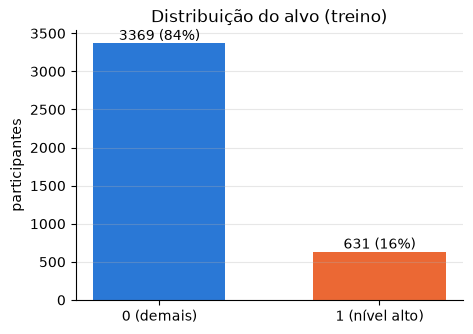

In [48]:
cont = np.bincount(ytr)
plt.figure(figsize=(5, 3.5))
plt.bar(["0 (demais)", "1 (nível alto)"], cont, color=[AZUL, LARANJA], width=0.6)
for i, c in enumerate(cont):
    plt.text(i, c, f"{c} ({c / len(ytr):.0%})", ha="center", va="bottom")
plt.title("Distribuição do alvo (treino)")
plt.ylabel("participantes")
plt.grid(axis="x")
plt.show()

As classes estão desbalanceadas, só uns 16% são classe 1. Um modelo que chuta sempre 0 já acerta 84%, então só a acurácia não serve pra comparar. Por isso usamos a **acurácia balanceada**, que é a média do acerto de cada classe (0.5 = chute). Também olhamos precisão, recall e F1 da classe 1.

Agora a porcentagem da classe 1 (nível socioeconômico alto) por algumas variáveis:

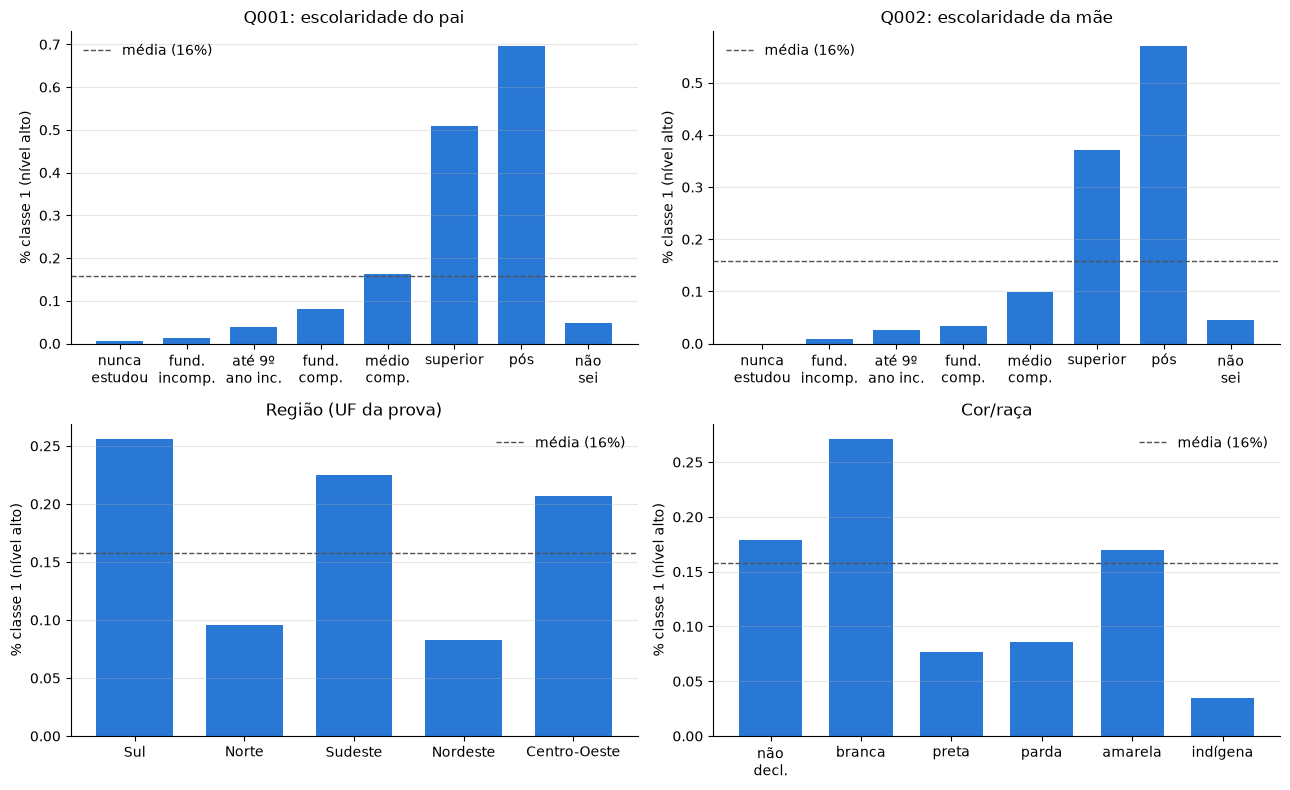

In [49]:
UF_REGIAO = {}
for uf in ["AC", "AP", "AM", "PA", "RO", "RR", "TO"]: UF_REGIAO[uf] = "Norte"
for uf in ["AL", "BA", "CE", "MA", "PB", "PE", "PI", "RN", "SE"]: UF_REGIAO[uf] = "Nordeste"
for uf in ["DF", "GO", "MT", "MS"]: UF_REGIAO[uf] = "Centro-Oeste"
for uf in ["ES", "MG", "RJ", "SP"]: UF_REGIAO[uf] = "Sudeste"
for uf in ["PR", "RS", "SC"]: UF_REGIAO[uf] = "Sul"

def grafico_taxa(valores, titulo, ax, rotulos=None):
    cats = sorted(set(valores), key=lambda s: (len(s), s))
    cats = [c for c in cats if (valores == c).sum() >= 20]
    taxas = [ytr[valores == c].mean() for c in cats]
    nomes = [rotulos.get(c, c) for c in cats] if rotulos else cats
    ax.bar(nomes, taxas, color=AZUL, width=0.7)
    ax.axhline(ytr.mean(), color=CINZA, ls="--", lw=1, label=f"média ({ytr.mean():.0%})")
    ax.set_title(titulo)
    ax.set_ylabel("% classe 1 (nível alto)")
    ax.grid(axis="x")
    ax.legend(frameon=False)

fig, axs = plt.subplots(2, 2, figsize=(13, 8))
grafico_taxa(D_tr[:, col["Q001"]], "Q001: escolaridade do pai", axs[0, 0],
             {"A": "nunca\nestudou", "B": "fund.\nincomp.", "C": "até 9º\nano inc.", "D": "fund.\ncomp.",
              "E": "médio\ncomp.", "F": "superior", "G": "pós", "H": "não\nsei"})
grafico_taxa(D_tr[:, col["Q002"]], "Q002: escolaridade da mãe", axs[0, 1],
             {"A": "nunca\nestudou", "B": "fund.\nincomp.", "C": "até 9º\nano inc.", "D": "fund.\ncomp.",
              "E": "médio\ncomp.", "F": "superior", "G": "pós", "H": "não\nsei"})
regiao = np.array([UF_REGIAO[u] for u in D_tr[:, col["SG_UF_PROVA"]]])
grafico_taxa(regiao, "Região (UF da prova)", axs[1, 0])
grafico_taxa(D_tr[:, col["TP_COR_RACA"]], "Cor/raça", axs[1, 1],
             {"0": "não\ndecl.", "1": "branca", "2": "preta", "3": "parda", "4": "amarela", "5": "indígena"})
plt.tight_layout()
plt.show()

O que dá pra ver:
- **escolaridade do pai (Q001) e da mãe (Q002)** são o que mais separa: quando o pai tem superior ou pós a taxa vai pra 50-70%, e com a mãe pra 37-57%. Quando os pais têm só o fundamental a taxa fica perto de 0%.
- **região**: Sul, Sudeste e Centro-Oeste ficam acima da média (21-26%), Norte e Nordeste bem abaixo (8-10%).
- **cor/raça**: brancos ficam acima da média (27%), pretos e pardos abaixo (8-9%).

Também fizemos a matriz de correlação de algumas perguntas (transformando as letras em 0, 1, 2, ...) com o alvo:

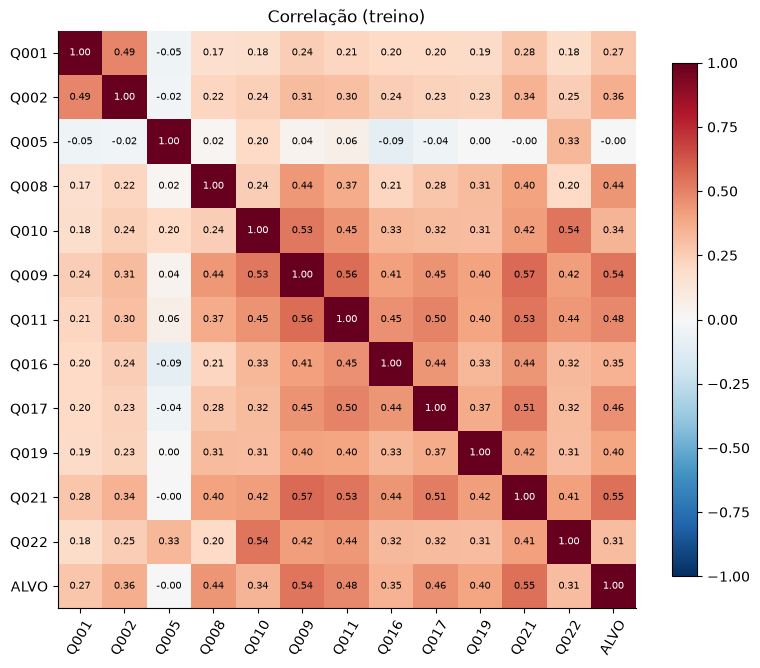

In [50]:
LETRAS = "ABCDEFGHIJKLMNOPQ"
perguntas = ["Q001", "Q002", "Q005", "Q008", "Q010", "Q009", "Q011", "Q016", "Q017", "Q019", "Q021", "Q022"]
M = []
for c in perguntas:
    M.append([LETRAS.index(v) if v in LETRAS else float(v) for v in D_tr[:, col[c]]])
M = np.column_stack(M + [ytr])
nomes = perguntas + ["ALVO"]
C = np.corrcoef(M, rowvar=False)

plt.figure(figsize=(8, 7))
plt.imshow(C, cmap="RdBu_r", vmin=-1, vmax=1)
plt.xticks(range(len(nomes)), nomes, rotation=60)
plt.yticks(range(len(nomes)), nomes)
for i in range(len(nomes)):
    for j in range(len(nomes)):
        plt.text(j, i, f"{C[i, j]:.2f}", ha="center", va="center", fontsize=7,
                 color="white" if abs(C[i, j]) > 0.6 else "black")
plt.grid(False)
plt.colorbar(shrink=0.8)
plt.title("Correlação (treino)")
plt.tight_layout()
plt.show()

As perguntas Q009 (banheiros), Q021 (computador), Q011 (carro), Q017, Q008 (empregada doméstica) são as mais correlacionadas com o alvo (0.44 a 0.55), e também são bem correlacionadas entre si, porque todas medem mais ou menos o nível socioeconômico da família. A Q005 (pessoas na casa) praticamente não tem correlação com o alvo.

## 2. Pré-processamento

O que fizemos:
- Q003, Q004 e Q007 (ocupação dos pais e renda) **não** entram como variáveis, porque são elas que definem o alvo. Se entrassem, o modelo só ia copiar a regra
- as perguntas com ordem (escolaridade, quantidade de bens, faixa etária, pessoas na casa) viram números 0, 1, 2, ... na ordem das alternativas
- "não sei" na Q001 e Q002 não tem lugar nessa ordem, então substituímos pela mediana do treino
- perguntas de sim/não e sexo viram 0/1
- região e cor/raça viram dummies. A categoria mais comum fica de referência (sem coluna). Amarela, indígena e não declarado têm poucos casos e juntamos em "outras"
- padronização com o `StandardScaler` da biblioteca, feita **dentro do fit** de cada modelo, pra média e desvio virem só dos folds de treino na validação cruzada
- balanceamento: também dentro do fit, sorteamos da classe 0 o mesmo número de exemplos da classe 1. Sem isso os modelos quase só respondiam 0. A validação e o teste continuam com a proporção original

In [51]:
# Q003, Q004 e Q007 ficam de fora: elas formam o alvo
ORDINAIS = ["TP_FAIXA_ETARIA", "Q001", "Q002", "Q005", "Q008", "Q009", "Q010",
            "Q011", "Q012", "Q013", "Q018", "Q021", "Q022"]
BINARIAS = ["Q006", "Q014", "Q015", "Q016", "Q017", "Q019", "Q020"]   # A = não, B = sim
NAO_SEI = {"Q001": "H", "Q002": "H"}                                  # letra do "não sei" em cada pergunta
COR = {"1": "branca", "2": "preta", "3": "parda"}                      # o resto vira "outras"

def codigo(c, v):
    if NAO_SEI.get(c) == v:
        return np.nan
    if v in LETRAS:
        return LETRAS.index(v)
    return float(v)

def categorias(D):
    regiao = np.array([UF_REGIAO[u] for u in D[:, col["SG_UF_PROVA"]]])
    cor = np.array([COR.get(c, "outras") for c in D[:, col["TP_COR_RACA"]]])
    return {"REGIAO": regiao, "COR": cor}

# mediana pro "não sei" e categorias das dummies: tudo calculado só no treino
mediana = {}
for c in NAO_SEI:
    mediana[c] = np.nanmedian([codigo(c, v) for v in D_tr[:, col[c]]])

niveis = {}
for nome, v in categorias(D_tr).items():
    cats, n = np.unique(v, return_counts=True)
    ref = cats[np.argmax(n)]
    niveis[nome] = [c for c in cats if c != ref]
    print(nome, "-> referência:", ref)

def montar_X(D):
    colunas, nomes = [], []
    for c in ORDINAIS:
        x = np.array([codigo(c, v) for v in D[:, col[c]]], dtype=float)
        if c in mediana:
            x[np.isnan(x)] = mediana[c]
        colunas.append(x)
        nomes.append(c)
    for c in BINARIAS:
        colunas.append((D[:, col[c]] == "B").astype(float))
        nomes.append(c)
    colunas.append((D[:, col["TP_SEXO"]] == "F").astype(float))
    nomes.append("SEXO_F")
    for nome, v in categorias(D).items():
        for cat in niveis[nome]:   # se aparecer categoria nova no teste ela fica tudo 0 (= referência)
            colunas.append((v == cat).astype(float))
            nomes.append(f"{nome}_{cat}")
    return np.column_stack(colunas), nomes

X_train, feature_names = montar_X(D_tr)
X_test, _ = montar_X(D_te)
print("X_train:", X_train.shape, "X_test:", X_test.shape)

REGIAO -> referência: Nordeste
COR -> referência: parda
X_train: (4000, 28) X_test: (1000, 28)


## 3. Comparação de modelos

Testamos esses modelos da biblioteca:
- **baseline**: chuta sempre a classe mais comum (serve só de referência)
- **regressão logística**: learning rate 0.1 e 0.5, 500 iterações
- **LDA**
- **KNN**: K = 5, 15 e 31
- **árvore de decisão**: profundidade 3, 5 e 8

O `KFold` da biblioteca precisa de uma classe com `fit` e `predict`, então a função `com_preprocessamento` monta essa classe já com o balanceamento e a padronização dentro.

In [52]:
class Baseline:
    def fit(self, X, y):
        self.classe = np.bincount(y).argmax()
        return self
    def predict(self, X):
        return np.full(len(X), self.classe)

class Arvore(DecisionTreeClassification):
    # na biblioteca a árvore treina com adjust(), mas o KFold chama fit()
    def fit(self, X, y):
        return self.adjust(X, y)

def subamostrar(X, y):
    # pega toda a classe 1 e sorteia o mesmo tanto da classe 0
    r = np.random.default_rng(SEED)
    i1 = np.flatnonzero(y == 1)
    i0 = r.choice(np.flatnonzero(y == 0), size=len(i1), replace=False)
    i = r.permutation(np.concatenate([i0, i1]))
    return X[i], y[i]

def com_preprocessamento(criar_modelo, balancear=True):
    class Modelo:
        def __init__(self, hip=None):
            pass   # os hiperparametros já vão dentro do criar_modelo
        def fit(self, X, y):
            if balancear:
                X, y = subamostrar(X, y)
            self.scaler = StandardScaler().fit(X)
            self.modelo = criar_modelo()
            self.modelo.fit(self.scaler.transform(X), y)
            return self
        def predict(self, X):
            return self.modelo.predict(self.scaler.transform(X))
    return Modelo

A biblioteca não tem métricas de classificação (só o risco empírico com perda 0-1), então fizemos a matriz de confusão e as métricas aqui:

In [53]:
def matriz_confusao(pred, real):
    # linha = classe real, coluna = classe prevista
    M = np.zeros((2, 2), dtype=int)
    for a in (0, 1):
        for b in (0, 1):
            M[a, b] = np.sum((real == a) & (pred == b))
    return M

def metricas(pred, real):
    (vn, fp), (fn, vp) = matriz_confusao(pred, real)
    recall = vp / (vp + fn) if vp + fn > 0 else 0
    especificidade = vn / (vn + fp) if vn + fp > 0 else 0
    precisao = vp / (vp + fp) if vp + fp > 0 else 0
    f1 = 2 * precisao * recall / (precisao + recall) if precisao + recall > 0 else 0
    return {"acurácia": (vp + vn) / len(real),
            "acurácia bal.": (recall + especificidade) / 2,
            "precisão": precisao, "recall": recall, "F1": f1}

def acuracia_balanceada(pred, real):
    return metricas(pred, real)["acurácia bal."]

### Comparação com validação cruzada

K-fold com K = 5, sempre com a mesma semente, então todos os modelos usam os mesmos folds. Pra cada modelo ficamos com a configuração de maior acurácia balanceada. O teste não entra aqui.

(demora uns 2 minutos, o KNN e a regressão logística da biblioteca são lentos porque usam for)

In [54]:
grades = {
    "Baseline": [("-", lambda: Baseline(), False)],
    "Regressão logística": [("lr=0.1", lambda: Logistic_Regression(learning_rate=0.1, iterations=500), True),
                            ("lr=0.5", lambda: Logistic_Regression(learning_rate=0.5, iterations=500), True)],
    "LDA": [("-", lambda: LDA(), True)],
    "KNN": [("K=5", lambda: KNN(5), True),
            ("K=15", lambda: KNN(15), True),
            ("K=31", lambda: KNN(31), True)],
    "Árvore": [("prof=3", lambda: Arvore(max_depth=3, min_samples=10), True),
               ("prof=5", lambda: Arvore(max_depth=5, min_samples=10), True),
               ("prof=8", lambda: Arvore(max_depth=8, min_samples=10), True)],
}

melhor = {}
for nome, opcoes in grades.items():
    for desc, criar, bal in opcoes:
        classe = com_preprocessamento(criar, balancear=bal)
        score = KFold(classe, X_train, ytr, k=K, stat=acuracia_balanceada, seed=SEED).folds()
        print(f"{nome:20s} {desc:7s} acurácia balanceada (CV) = {score:.3f}")
        if nome not in melhor or score > melhor[nome][0]:
            melhor[nome] = (score, desc, classe)

print()
for nome, (score, desc, _) in melhor.items():
    print("melhor", nome, "->", desc)

Baseline             -       acurácia balanceada (CV) = 0.500
Regressão logística  lr=0.1  acurácia balanceada (CV) = 0.878
Regressão logística  lr=0.5  acurácia balanceada (CV) = 0.881
LDA                  -       acurácia balanceada (CV) = 0.875
KNN                  K=5     acurácia balanceada (CV) = 0.842
KNN                  K=15    acurácia balanceada (CV) = 0.858
KNN                  K=31    acurácia balanceada (CV) = 0.863
Árvore               prof=3  acurácia balanceada (CV) = 0.835
Árvore               prof=5  acurácia balanceada (CV) = 0.854
Árvore               prof=8  acurácia balanceada (CV) = 0.848

melhor Baseline -> -
melhor Regressão logística -> lr=0.5
melhor LDA -> -
melhor KNN -> K=31
melhor Árvore -> prof=5


## 4. Validação

A validação cruzada acima já foi usada pra escolher os hiperparâmetros sem tocar no teste. Pra ver melhor o over/underfitting, fizemos a curva da árvore variando a profundidade, comparando o acerto no treino e na validação cruzada:

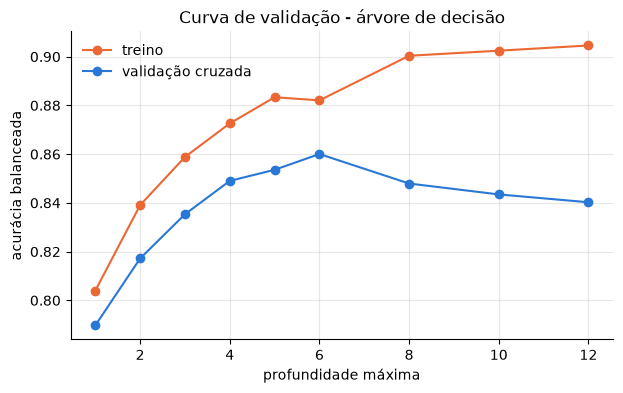

In [55]:
profs = [1, 2, 3, 4, 5, 6, 8, 10, 12]
score_cv, score_treino = [], []
for p in profs:
    classe = com_preprocessamento(lambda p=p: Arvore(max_depth=p, min_samples=10))
    score_cv.append(KFold(classe, X_train, ytr, k=K, stat=acuracia_balanceada, seed=SEED).folds())
    modelo = classe().fit(X_train, ytr)
    score_treino.append(acuracia_balanceada(modelo.predict(X_train), ytr))

plt.figure(figsize=(7, 4))
plt.plot(profs, score_treino, "o-", color=LARANJA, label="treino")
plt.plot(profs, score_cv, "o-", color=AZUL, label="validação cruzada")
plt.xlabel("profundidade máxima")
plt.ylabel("acurácia balanceada")
plt.title("Curva de validação - árvore de decisão")
plt.legend(frameon=False)
plt.show()

Com profundidade pequena as duas curvas estão baixas (underfitting). Depois de uns 6 níveis o treino continua subindo mas a validação cai: a árvore começa a decorar o treino (overfitting). O melhor fica por volta de 5-6 de profundidade.

## 5. Avaliação final

Agora sim usamos o teste, uma vez só. Cada modelo escolhido é treinado de novo com o treino inteiro.

In [56]:
modelos, resultados = {}, {}
for nome, (score, desc, classe) in melhor.items():
    modelos[nome] = classe().fit(X_train, ytr)
    resultados[nome] = metricas(modelos[nome].predict(X_test), yte)

print(f"{'modelo':28s} {'CV':>6s}" + "".join(f"{m:>15s}" for m in resultados["Baseline"]))
for nome, r in resultados.items():
    print(f"{nome + ' (' + melhor[nome][1] + ')':28s} {melhor[nome][0]:6.3f}" + "".join(f"{v:15.3f}" for v in r.values()))

# o modelo final é escolhido pela validação cruzada e não pelo teste
escolhido = max([n for n in melhor if n != "Baseline"], key=lambda n: melhor[n][0])
print("\nmodelo escolhido pela CV:", escolhido)

modelo                           CV       acurácia  acurácia bal.       precisão         recall             F1
Baseline (-)                  0.500          0.824          0.500          0.000          0.000          0.000
Regressão logística (lr=0.5)  0.881          0.859          0.876          0.562          0.903          0.693
LDA (-)                       0.875          0.859          0.874          0.562          0.898          0.691
KNN (K=31)                    0.863          0.841          0.866          0.528          0.903          0.667
Árvore (prof=5)               0.854          0.816          0.841          0.487          0.881          0.628

modelo escolhido pela CV: Regressão logística


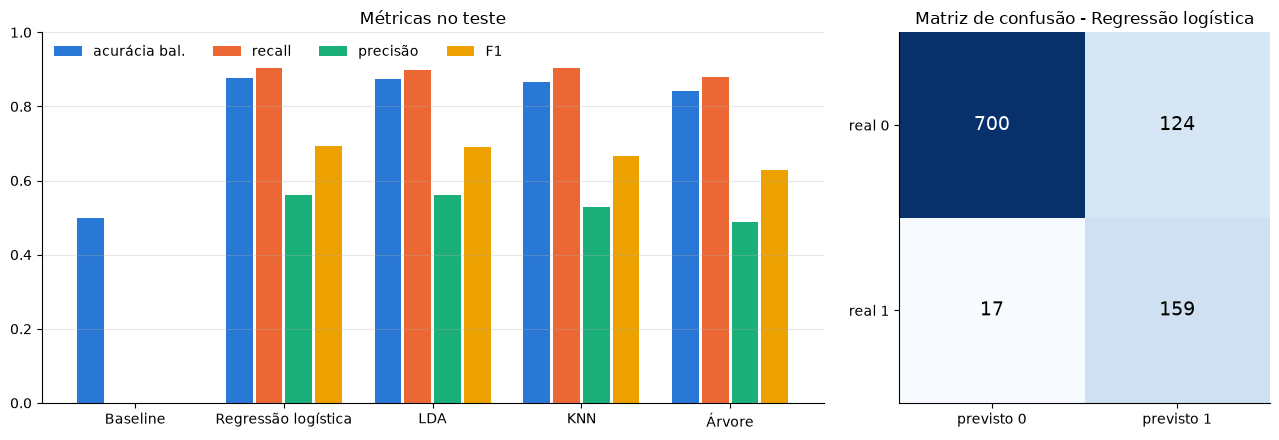

In [57]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [2, 1]})

nomes_met = ["acurácia bal.", "recall", "precisão", "F1"]
cores = [AZUL, LARANJA, "#1baf7a", "#eda100"]
x = np.arange(len(resultados))
for i, m in enumerate(nomes_met):
    axs[0].bar(x + (i - 1.5) * 0.2, [resultados[n][m] for n in resultados], 0.18, color=cores[i], label=m)
axs[0].set_xticks(x, list(resultados))
axs[0].set_ylim(0, 1)
axs[0].set_title("Métricas no teste")
axs[0].legend(frameon=False, ncol=4, loc="upper left")
axs[0].grid(axis="x")

mc = matriz_confusao(modelos[escolhido].predict(X_test), yte)
axs[1].imshow(mc, cmap="Blues")
for i in range(2):
    for j in range(2):
        axs[1].text(j, i, mc[i, j], ha="center", va="center", fontsize=14,
                    color="white" if mc[i, j] > mc.max() / 2 else "black")
axs[1].set_xticks([0, 1], ["previsto 0", "previsto 1"])
axs[1].set_yticks([0, 1], ["real 0", "real 1"])
axs[1].grid(False)
axs[1].set_title(f"Matriz de confusão - {escolhido}")
plt.tight_layout()
plt.show()

Como o teste tem só 1000 pessoas (176 da classe 1), calculamos também um intervalo de confiança com bootstrap: reamostramos as previsões do teste 2000 vezes (sem treinar de novo).

In [58]:
pred = modelos[escolhido].predict(X_test)
r = np.random.default_rng(SEED)
boot = []
for _ in range(2000):
    i = r.integers(0, len(yte), len(yte))
    boot.append(acuracia_balanceada(pred[i], yte[i]))
print(f"{escolhido}: acurácia balanceada no teste = {resultados[escolhido]['acurácia bal.']:.3f}")
print(f"IC 95% (bootstrap): [{np.percentile(boot, 2.5):.3f}, {np.percentile(boot, 97.5):.3f}]")

Regressão logística: acurácia balanceada no teste = 0.876
IC 95% (bootstrap): [0.850, 0.901]


## 6. Interpretação dos resultados

### Coeficientes da regressão logística

Com 2 classes, o efeito de cada variável no log-odds da classe 1 é `beta[:, 1] - beta[:, 0]` (a biblioteca guarda um beta por classe). Como as variáveis estão padronizadas, cada coeficiente é o efeito de aumentar 1 desvio padrão, e `exp(coef)` é por quanto a chance é multiplicada. Nas dummies a comparação é com a categoria de referência (Nordeste e parda).

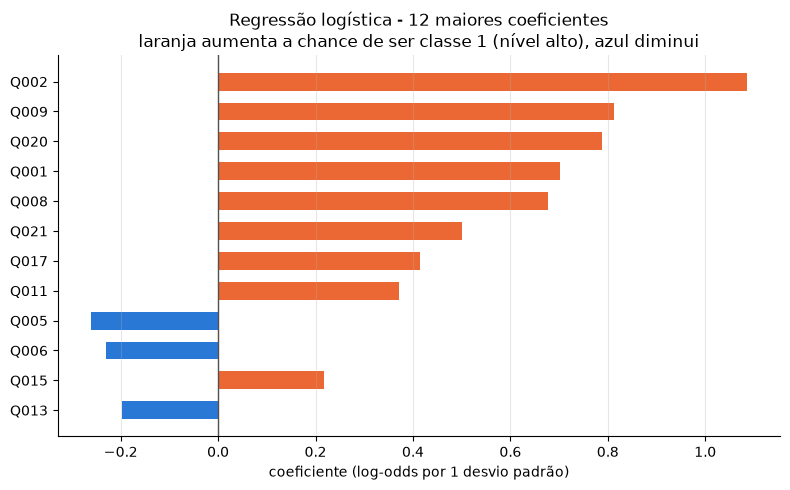

Q002                   coef = +1.09  -> chance x 2.96
Q009                   coef = +0.81  -> chance x 2.25
Q020                   coef = +0.79  -> chance x 2.20
Q001                   coef = +0.70  -> chance x 2.02
Q008                   coef = +0.68  -> chance x 1.97
Q021                   coef = +0.50  -> chance x 1.65
Q017                   coef = +0.41  -> chance x 1.51
Q011                   coef = +0.37  -> chance x 1.45
Q005                   coef = -0.26  -> chance x 0.77
Q006                   coef = -0.23  -> chance x 0.80
Q015                   coef = +0.22  -> chance x 1.24
Q013                   coef = -0.20  -> chance x 0.82


In [59]:
logistica = modelos["Regressão logística"].modelo
coef = logistica.beta[:, 1] - logistica.beta[:, 0]
ordem = np.argsort(np.abs(coef))[-12:]   # 12 maiores em módulo

plt.figure(figsize=(8, 5))
cores = [LARANJA if c > 0 else AZUL for c in coef[ordem]]
plt.barh([feature_names[i] for i in ordem], coef[ordem], color=cores, height=0.6)
plt.axvline(0, color=CINZA, lw=1)
plt.xlabel("coeficiente (log-odds por 1 desvio padrão)")
plt.title("Regressão logística - 12 maiores coeficientes\nlaranja aumenta a chance de ser classe 1 (nível alto), azul diminui")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

for i in ordem[::-1]:
    print(f"{feature_names[i]:22s} coef = {coef[i]:+.2f}  -> chance x {np.exp(coef[i]):.2f}")

### Importância por permutação

Outra forma de ver o que importa, e que serve pra qualquer modelo: embaralhamos uma coluna do teste por vez e vemos quanto a acurácia balanceada cai. Se cai muito, o modelo depende daquela variável.

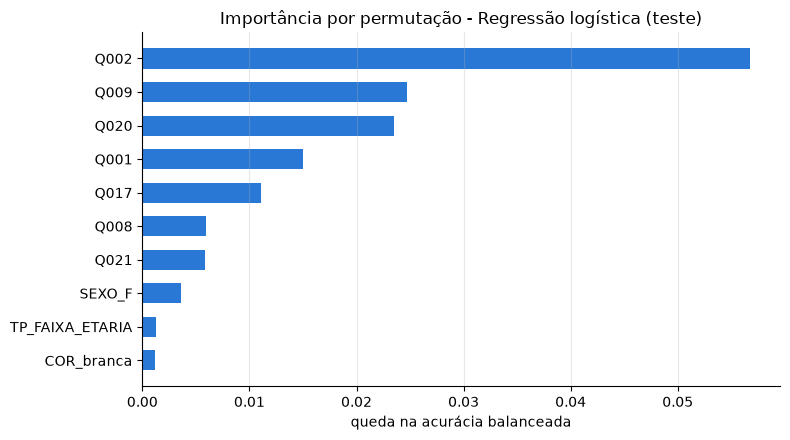

In [60]:
base = acuracia_balanceada(modelos[escolhido].predict(X_test), yte)
r = np.random.default_rng(SEED)
queda = np.zeros(X_test.shape[1])
for j in range(X_test.shape[1]):
    for _ in range(5):   # repete 5 vezes e tira a média pra diminuir o ruído
        Xp = X_test.copy()
        Xp[:, j] = r.permutation(Xp[:, j])
        queda[j] += (base - acuracia_balanceada(modelos[escolhido].predict(Xp), yte)) / 5
ordem = np.argsort(queda)[-10:]

plt.figure(figsize=(8, 4.5))
plt.barh([feature_names[i] for i in ordem], queda[ordem], color=AZUL, height=0.6)
plt.xlabel("queda na acurácia balanceada")
plt.title(f"Importância por permutação - {escolhido} (teste)")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

### Conclusões

- Todos os modelos ficaram bem acima do baseline (0.5): no teste deram entre 0.84 e 0.88 de acurácia balanceada. Então dá pra prever bem se a família tem nível socioeconômico alto (pais com ocupação dos grupos 4/5 e renda acima de 3 salários mínimos) mesmo **sem** usar as perguntas de ocupação e renda, só com escolaridade dos pais e bens da casa.
- A regressão logística (~0.88) e o LDA (~0.875) foram os melhores na validação cruzada e ficaram praticamente empatados. O KNN e a árvore ficaram um pouco atrás. Faz sentido, porque a relação parece quase linear (mais escolaridade e mais bens → mais chance), então um modelo simples já resolve. O modelo escolhido foi a regressão logística, com acurácia balanceada de 0.876 no teste (IC 95% de 0.85 a 0.90).
- O recall ficou bem alto (~0.90): o modelo acha quase todo mundo da classe 1. Já a precisão ficou mais baixa (~0.56), ou seja, parte de quem é classe 0 é classificada como 1. Isso é efeito do balanceamento, que troca precisão por recall.
- Na regressão logística, os maiores coeficientes positivos foram escolaridade da mãe (Q002) e do pai (Q001), número de banheiros (Q009), acesso a internet (Q020) e empregada doméstica (Q008). O número de pessoas na casa (Q005) diminui a chance: com os mesmos bens, mais pessoas na casa = menos dinheiro por pessoa.
- Uma coisa interessante: na análise exploratória Sul e Sudeste tinham taxa bem **maior** que o Nordeste, mas na regressão logística os coeficientes de região ficaram perto de zero (e o Norte até positivo). Ou seja, a diferença entre regiões é quase toda explicada pela escolaridade dos pais e pelos bens da casa.
- Na importância por permutação a escolaridade da mãe (Q002) foi a que mais derrubou o resultado (~0.06), seguida de Q009, Q020 e Q001. As outras quedas foram pequenas porque as variáveis de bens são muito correlacionadas: quando embaralhamos uma, as outras ainda carregam quase a mesma informação.

### Limitações

- Usamos só 5000 dos ~4.5 milhões de participantes elegíveis, então as métricas têm alguns pontos de incerteza (ver o intervalo do bootstrap).
- A definição do alvo (grupos 4/5 e renda acima de R$ 4.554) é uma escolha nossa. Outro corte de renda ou de ocupação muda a proporção da classe 1 e os resultados.
- Quem não sabe a ocupação de um dos pais é tratado como "não está no grupo 4/5" para aquele pai. Só tiramos quem não sabe a dos dois.
- Como as variáveis de bens e escolaridade são correlacionadas, o peso fica dividido entre elas e cada coeficiente sozinho não deve ser levado muito ao pé da letra. E são só associações, não causa e efeito.
- A mediana do "não sei" e as categorias de referência foram calculadas no treino inteiro e não em cada fold, mas isso quase não deve mudar a validação cruzada.
- Tanto o alvo quanto as variáveis são respostas do próprio participante no questionário.